# 6 · Explainable AI — why each model flags what it flags

**CRISP-DM phase 5 (Evaluation), XAI part.** Previous: [`5_Evaluation.ipynb`](5_Evaluation.ipynb) · Next: deployment (`deployment/`)

XAI here is a set of explanation methods applied to the trained models, not a new model (FR, section 5). Methods, from the FR plan:

| Model | Method | Target (a fixed scalar) |
|---|---|---|
| A — DeepLabV3+ | **Seg-Grad-CAM** on the ASPP branches and the decoder | mean anomaly **logit** inside a fixed region |
| B — pixel AE | **error map** + Grad-CAM on the bottleneck `code` | mean squared reconstruction error inside a fixed region |
| B — feature AE | **error map** + Grad-CAM on the bottleneck `code` | mean feature reconstruction error inside a fixed region (16-px cells) |
| C — CNN / U-Nets | **Seg-Grad-CAM** on the last decoder layer (FR: a decoder layer, not the bottleneck, which ignores the skips) | mean anomaly **logit** inside a fixed region |

**Rules.** Validation images only (no explanation is computed on test, so nothing here can leak into a choice). The region is fixed *before* the gradients are computed. A heatmap is checked with **deletion / insertion** against random orders. Two warnings from FR hold throughout: an **error map is a detection map, not a causal explanation**, and a Grad-CAM heatmap **does not replace a segmentation metric**.

## 0. Setup

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

from roadanomaly import data_pipeline as dp, evaluation, xai
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import Predictor, available_models
from roadanomaly.protocol import IMG_SIZE, SEED

import warnings
warnings.filterwarnings('ignore')

keras.utils.set_random_seed(SEED)
GPU_NAME = setup_gpu()
FIG_DIR = dp.FIG_DIR

predictors = {name: Predictor(dp.MODELS_DIR / name) for name in available_models(dp.MODELS_DIR)}
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
gt_val = y_val[..., 0].astype(bool)
outputs = {name: p.predict(x_val) for name, p in predictors.items()}
print("Models:", list(predictors))

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)


I0000 00:00:1793564918.976986 3127552 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


I0000 00:00:1793564925.868677 3128879 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Models: ['A_deeplabv3plus', 'B_feature_ae', 'B_pixel_ae', 'C_cnn', 'C_unet', 'C_unet_resnet50']


## 1. Common cases
The same two validation images are explained for every model: the **success** case (highest F1 averaged over the models) and the **failure** case (lowest). They are chosen from the validation scores only.

In [2]:
f1 = pd.DataFrame({name: [s["f1"] for s in evaluation.mask_report(gt_val, out["masks"])["pixel"]["per_image"]]
                   for name, out in outputs.items()}, index=[f[:30] for f in val_frames])
SUCCESS, FAILURE = int(np.argmax(f1.mean(axis=1).values)), int(np.argmin(f1.mean(axis=1).values))
print("success case:", val_frames[SUCCESS], "| failure case:", val_frames[FAILURE])
f1.round(3)

success case: animals04_17_animal_casualties_so_far_in_2006 | failure case: obstacles08_boulder2


,A_deeplabv3plus,B_feature_ae,B_pixel_ae,C_cnn,C_unet,C_unet_resnet50
animals04_17_animal_casualties,0.889,0.763,0.280,0.850,0.791,0.884
animals10_bovine_cattle_beside,0.918,0.736,0.407,0.667,0.000,0.918
animals19_Porte_de_Roubaix,0.584,0.676,0.206,0.287,0.359,0.577
animals27_wildlife_bear,0.938,0.537,0.037,0.852,0.864,0.956
animals30,0.827,0.633,0.344,0.602,0.708,0.818
cones01_Beeston_MMB_A6_Middle_,0.641,0.242,0.209,0.316,0.636,0.691
obstacles07_czech_hedgehog,0.307,0.569,0.422,0.682,0.762,0.682
obstacles08_boulder2,0.358,0.343,0.109,0.026,0.017,0.239
vehicle03_Fuhrwerke_in_China,0.794,0.677,0.225,0.245,0.017,0.017


## 2. Explanation functions
One function per model type, all built on `roadanomaly.xai.grad_cam`. For the **feature AE** the input of the autoencoder is the 22x40 map of standardised VGG16 features, so its region is the predicted mask reduced to cells (a cell belongs to the region when at least half of its pixels do).

In [3]:
SEG_LAYERS = ["decoder_2", "aspp_1x1", "aspp_rate_6", "aspp_rate_12", "aspp_rate_18"]

def to_cells(region, cell_shape):
    """Pixel region -> cell region (a cell is in the region if >= 50 % of its pixels are)."""
    resized = tf.image.resize(region.astype("float32")[..., None], cell_shape, method="area").numpy()[..., 0]
    return resized >= 0.5

def explain(name, index, region):
    """{layer: (heatmap, raw max)} for one model, one validation image and one fixed region."""
    predictor = predictors[name]
    if predictor.model_type == "segmentation":
        # the decoder layer of any segmentation model, then the DeepLabV3+ ASPP branches when they exist
        names = {layer.name for layer in predictor.model.layers}
        layers = [xai.default_segmentation_layer(predictor.model)] + [l for l in SEG_LAYERS[1:] if l in names]
        return {layer: xai.grad_cam(predictor.model, x_val[index], layer, xai.logit_target(region),
                                    output_name="anomaly_logits") for layer in layers}
    if predictor.model_type == "pixel_autoencoder":
        return {"code": xai.grad_cam(predictor.model, x_val[index], "code", xai.reconstruction_target(region))}
    features = predictor.features(x_val[index:index + 1])[0]
    cells = to_cells(region, features.shape[:2])
    if not cells.any():
        return {}
    return {"code": xai.grad_cam(predictor.model, features, "code", xai.reconstruction_target(cells), size=IMG_SIZE)}

def detection_map(name, index):
    """What the model outputs before the threshold: probability (A, C) or post-processed error score (B)."""
    return outputs[name]["scores"][index]

## 3. The common XAI board (success case)
Columns: image → ground truth → predicted mask → detection map (probability or error score) → Grad-CAM of the predicted region. For segmentation models the last decoder layer is shown here (`decoder_2` for DeepLabV3+); all DeepLabV3+ layers are compared in section 4.

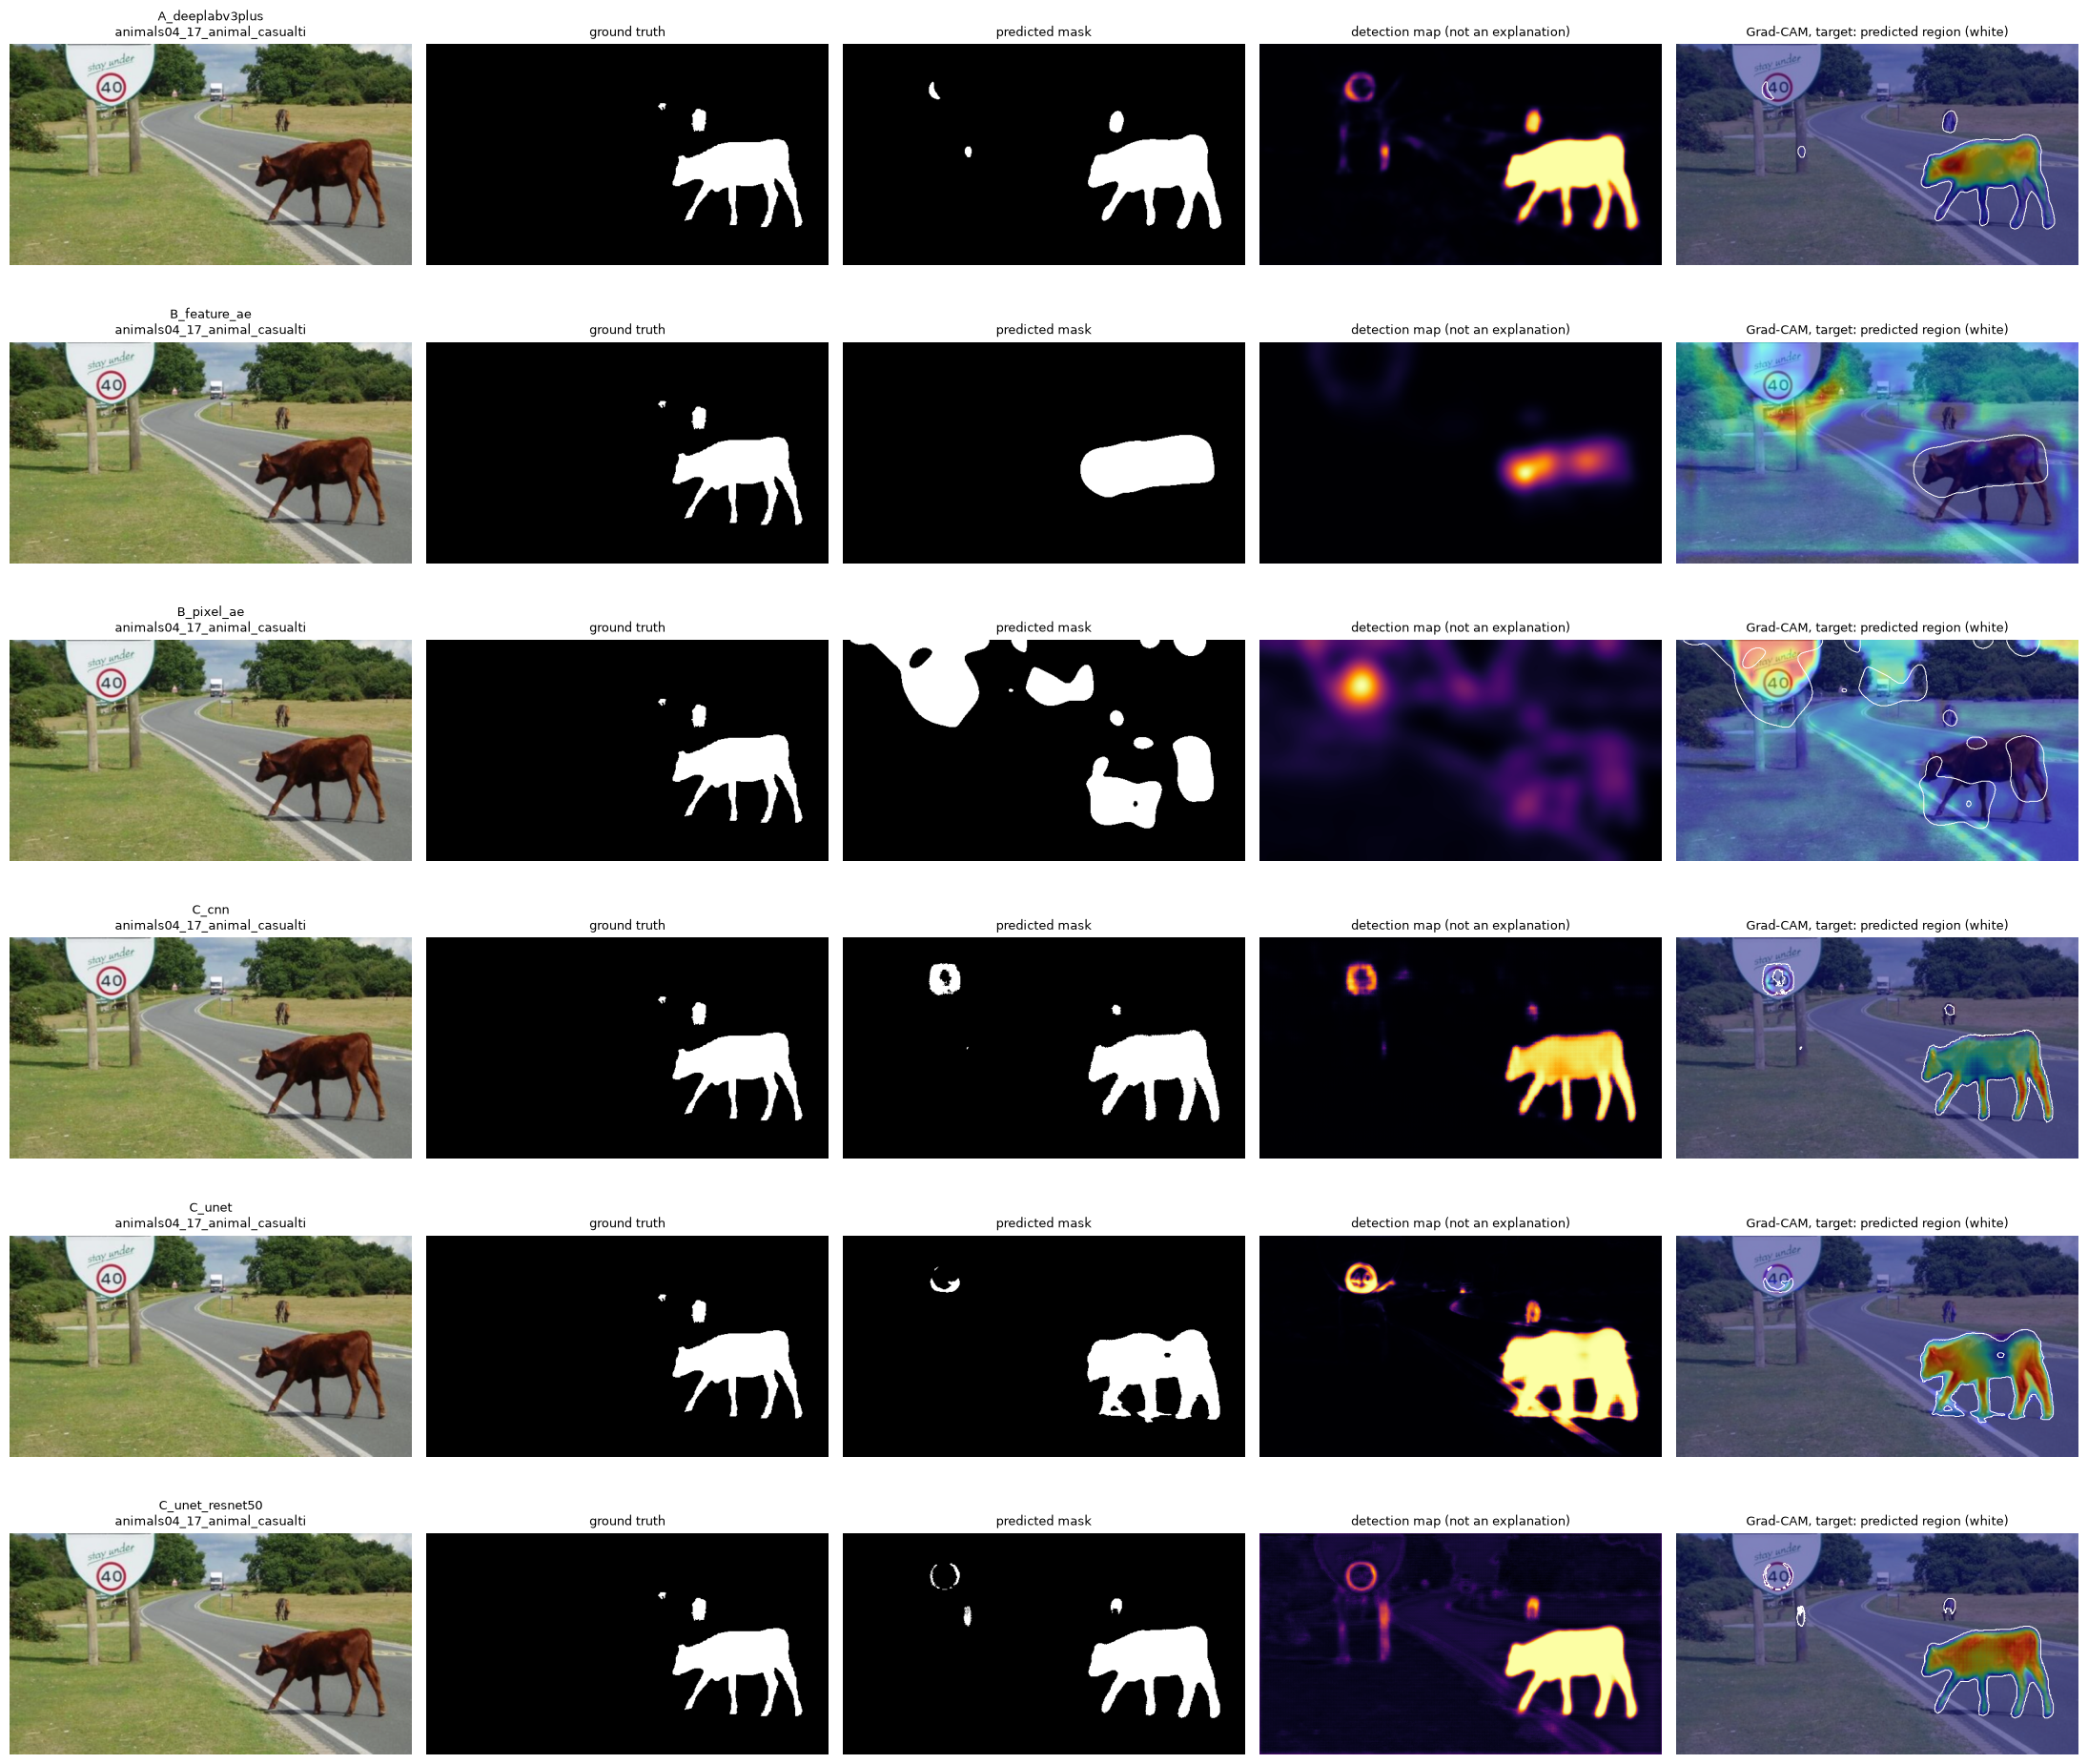

In [4]:
def board(index, region_of, title, path):
    fig, ax = plt.subplots(len(predictors), 5, figsize=(22, 3.3 * len(predictors)), squeeze=False, tight_layout=True)
    for row, name in enumerate(predictors):
        region = region_of(name)
        maps = explain(name, index, region) if region.any() else {}
        cam, raw_max = next(iter(maps.values())) if maps else (np.zeros(IMG_SIZE), 0.0)   # decoder layer or code
        panels = [(x_val[index], f"{name}\n{val_frames[index][:28]}"), (gt_val[index], "ground truth"),
                  (outputs[name]["masks"][index], "predicted mask"),
                  (detection_map(name, index), "detection map (not an explanation)")]
        for col, (panel, label) in enumerate(panels):
            ax[row, col].imshow(panel, cmap="inferno" if col == 3 else ("gray" if panel.ndim == 2 else None))
            ax[row, col].set_title(label, fontsize=9)
        ax[row, 4].imshow(x_val[index]); ax[row, 4].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[row, 4].contour(region.astype(float), levels=[0.5], colors="white", linewidths=0.7)
        ax[row, 4].set_title(f"Grad-CAM, target: {title}" + (" (zero map)" if raw_max == 0 else ""), fontsize=9)
    for a in ax.flat:
        a.axis("off")
    plt.savefig(FIG_DIR / path, dpi=55)
    plt.show()

board(SUCCESS, lambda name: outputs[name]["masks"][SUCCESS].astype(bool), "predicted region (white)",
      "6_01_xai_board_success.png")

## 4. Segmentation models: which part of the network supports the prediction?
Seg-Grad-CAM for the decoder and each ASPP branch, same image and same predicted region. Each map is normalised by its own maximum, so colours compare *where* a layer looks, not *how much* it contributes. The global-pooling branch has no spatial detail and is not shown; the stride-4 low-level path of the decoder can bypass the ASPP (FR, 10.2).

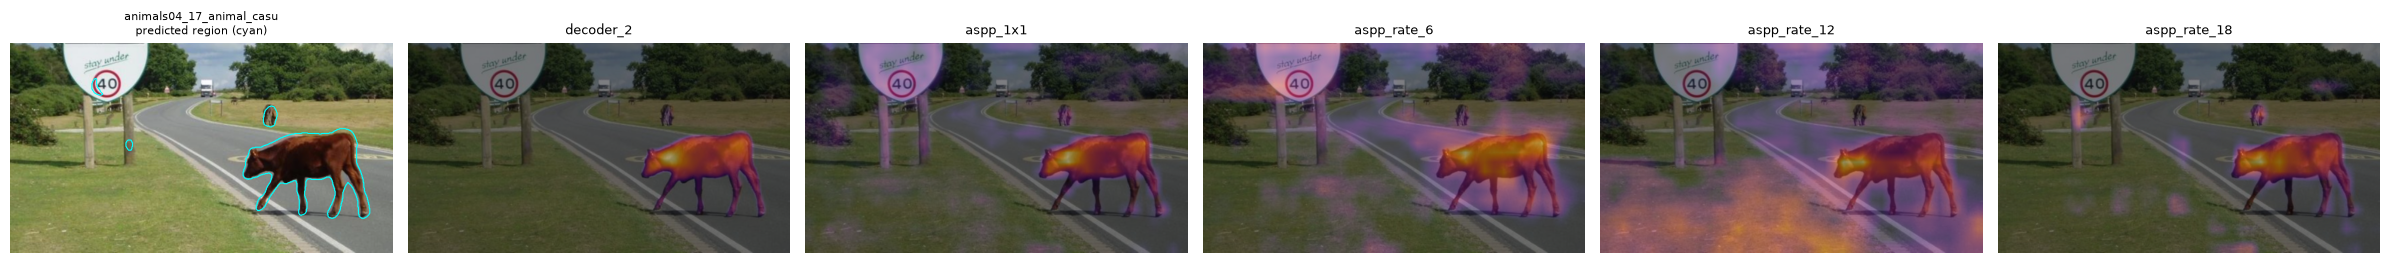

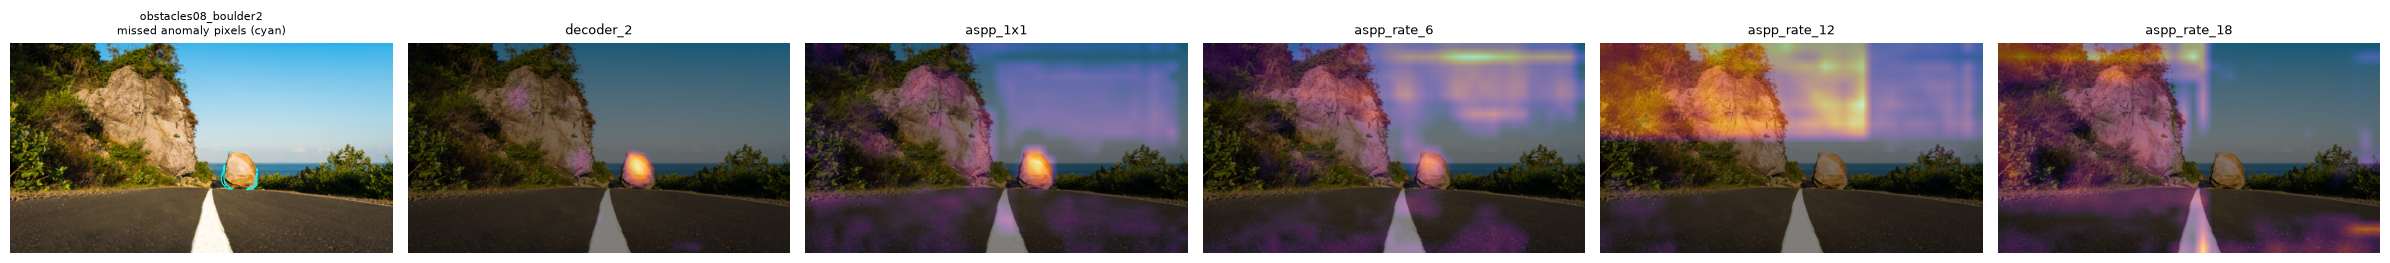

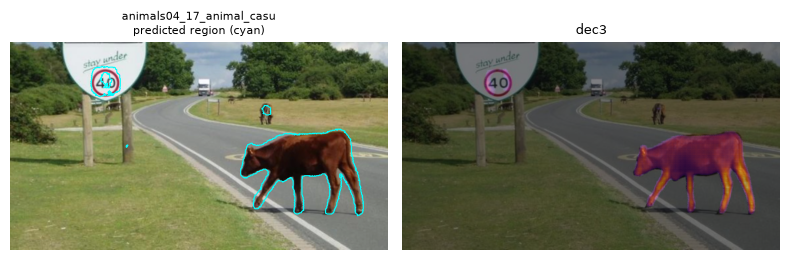

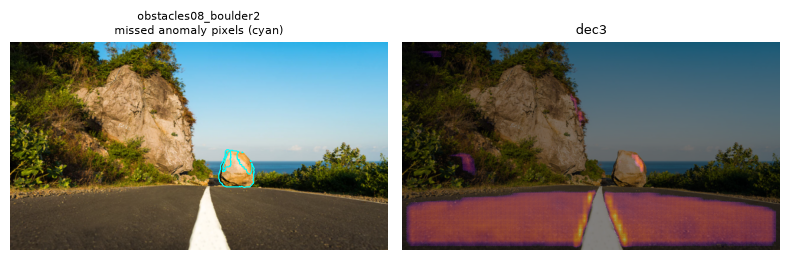

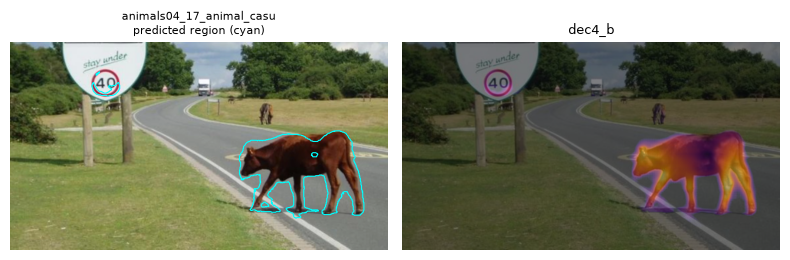

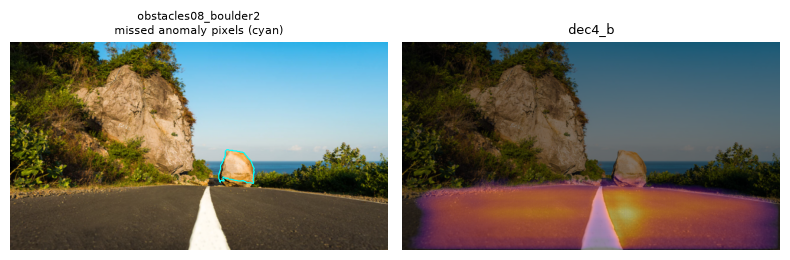

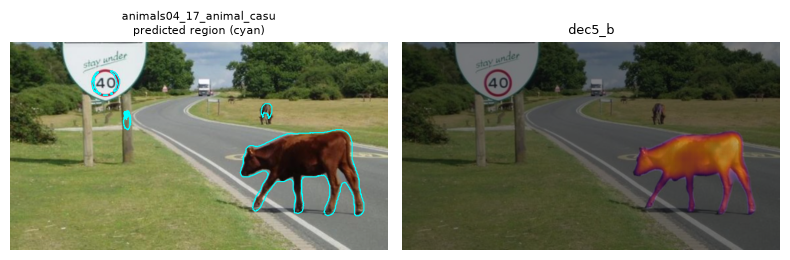

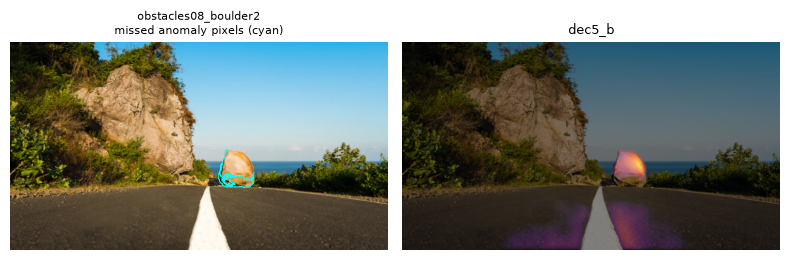

In [5]:
seg_models = [n for n, p in predictors.items() if p.model_type == "segmentation"]
for name in seg_models:
    for index, kind, region in [(SUCCESS, "predicted region", outputs[name]["masks"][SUCCESS].astype(bool)),
                                (FAILURE, "missed anomaly pixels", gt_val[FAILURE] & ~outputs[name]["masks"][FAILURE].astype(bool))]:
        if not region.any():
            print(f"{name}, {val_frames[index]}: empty {kind}, skipped")
            continue
        maps = explain(name, index, region)
        fig, ax = plt.subplots(1, len(maps) + 1, figsize=(4 * (len(maps) + 1), 3), tight_layout=True)
        ax[0].imshow(x_val[index]); ax[0].contour(region.astype(float), levels=[0.5], colors="cyan", linewidths=0.8)
        ax[0].set_title(f"{val_frames[index][:24]}\n{kind} (cyan)", fontsize=8)
        for a, (layer, (cam, raw_max)) in zip(ax[1:], maps.items()):
            a.imshow(x_val[index]); a.imshow(cam, cmap="inferno", alpha=0.5, vmin=0, vmax=1)
            a.set_title(layer + (" (zero map)" if raw_max == 0 else ""), fontsize=9)
        for a in ax:
            a.axis("off")
        plt.savefig(FIG_DIR / f"6_02_seg_gradcam_{name}_{'success' if index == SUCCESS else 'failure'}.png", dpi=60)
        plt.show()

## 5. Autoencoders: error maps and what drives them
For Binôme B the first explanation is the **error map**: it shows *where* the reconstruction fails. Grad-CAM on the bottleneck then asks which code positions raise the mean error of the predicted region. Because the bottleneck is coarse (4x4 code per 64-px patch for the pixel AE, 16-px cells for the feature AE), these maps are spatially coarse.

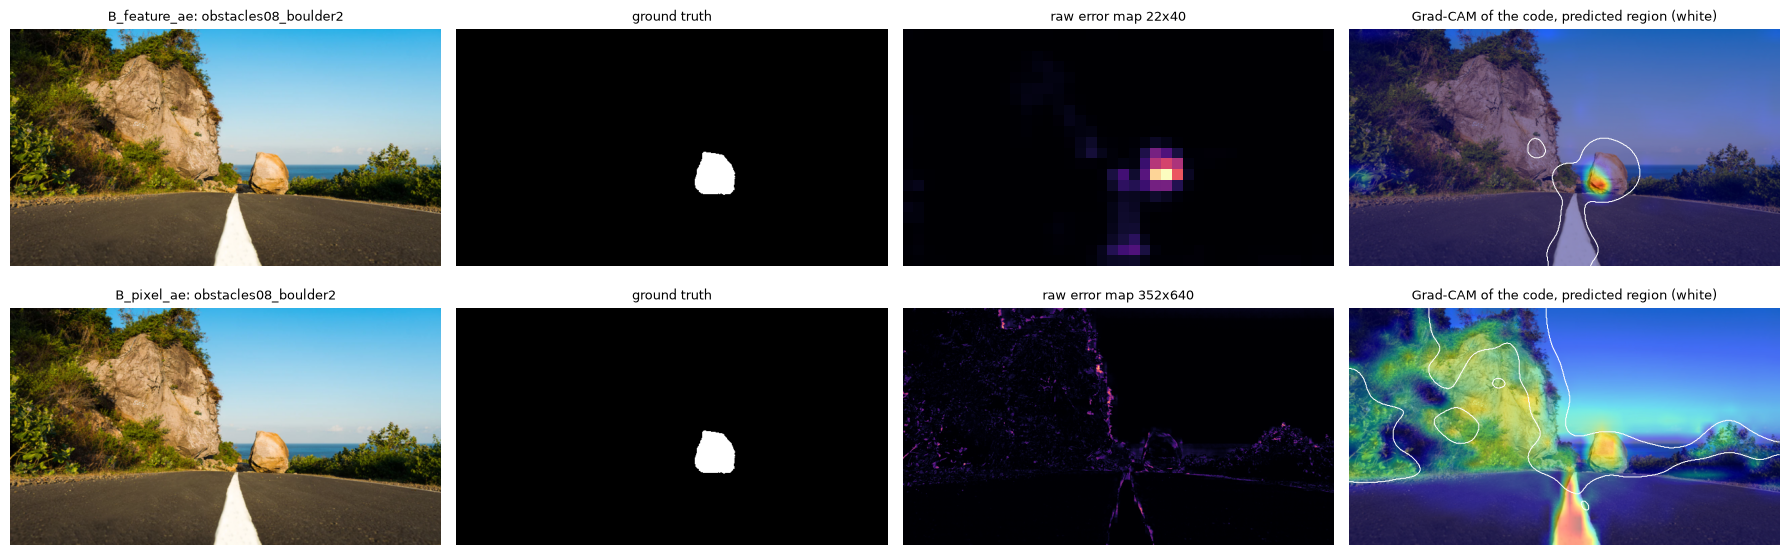

In [6]:
ae_models = [n for n, p in predictors.items() if p.model_type != "segmentation"]
fig, ax = plt.subplots(len(ae_models), 4, figsize=(18, 3.3 * len(ae_models)), squeeze=False, tight_layout=True)
for row, name in enumerate(ae_models):
    index = FAILURE
    region = outputs[name]["masks"][index].astype(bool)
    raw = predictors[name].raw_maps(x_val[index:index + 1])[0]
    maps = explain(name, index, region) if region.any() else {}
    cam, raw_max = maps.get("code", (np.zeros(IMG_SIZE), 0.0))
    panels = [(x_val[index], f"{name}: {val_frames[index][:26]}"), (gt_val[index], "ground truth"),
              (raw, f"raw error map {raw.shape[0]}x{raw.shape[1]}")]
    for col, (panel, label) in enumerate(panels):
        ax[row, col].imshow(panel, cmap="magma" if col == 2 else ("gray" if panel.ndim == 2 else None))
        ax[row, col].set_title(label, fontsize=9)
    ax[row, 3].imshow(x_val[index]); ax[row, 3].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax[row, 3].contour(region.astype(float), levels=[0.5], colors="white", linewidths=0.7)
    ax[row, 3].set_title("Grad-CAM of the code, predicted region (white)" + (" (zero map)" if raw_max == 0 else ""), fontsize=9)
for a in ax.flat:
    a.axis("off")
plt.savefig(FIG_DIR / "6_03_autoencoders_failure_case.png", dpi=60)
plt.show()

## 6. Faithfulness check: deletion and insertion
For the success case, image blocks of 32x32 px are ranked by the Grad-CAM map. **Deletion** replaces the top blocks with a blurred copy of the image; **insertion** restores them on top of the blurred copy. The tracked score is the model's target on the fixed region (mean logit for A, mean reconstruction error for B). A faithful map makes deletion fall and insertion rise **faster than random orders** (3 seeds). Areas under the curves are integrals of the target over the modified fraction, not percentages.

In [7]:
def target_score_fn(name, region):
    """batch of images -> the model's scalar target on the fixed region, for each image."""
    predictor = predictors[name]
    if predictor.model_type == "segmentation":
        logits = keras.Model(predictor.model.inputs, predictor.model.get_layer("anomaly_logits").output)
        return lambda batch: logits.predict(batch, verbose=0)[..., 0][:, region].mean(axis=1)
    raw_region = region if predictor.model_type == "pixel_autoencoder" else to_cells(region, (IMG_SIZE[0] // 16, IMG_SIZE[1] // 16))
    return lambda batch: predictor.raw_maps(batch)[:, raw_region].mean(axis=1)

faithfulness, curves = [], {}
for name in predictors:
    region = outputs[name]["masks"][SUCCESS].astype(bool)
    maps = explain(name, SUCCESS, region) if region.any() else {}
    if not maps:
        continue
    first_layer, (cam, _) = next(iter(maps.items()))   # decoder layer (segmentation) or code (autoencoders)
    result = xai.deletion_insertion(target_score_fn(name, region), x_val[SUCCESS], cam, block=32)
    curves[name] = result
    randoms = [result[k] for k in result if k.startswith("random")]
    faithfulness.append({"model": name, "map": first_layer,
                         "deletion AUC (map)": result["attribution"]["deletion_auc"],
                         "deletion AUC (random mean)": np.mean([r["deletion_auc"] for r in randoms]),
                         "insertion AUC (map)": result["attribution"]["insertion_auc"],
                         "insertion AUC (random mean)": np.mean([r["insertion_auc"] for r in randoms])})
faithfulness_df = pd.DataFrame(faithfulness)
faithfulness_df["map better on deletion"] = faithfulness_df["deletion AUC (map)"] < faithfulness_df["deletion AUC (random mean)"]
faithfulness_df["map better on insertion"] = faithfulness_df["insertion AUC (map)"] > faithfulness_df["insertion AUC (random mean)"]
faithfulness_df.round(3)

,model,map,deletion AUC (map),deletion AUC (random mean),insertion AUC (map),insertion AUC (random mean),map better on deletion,map better on insertion
0,A_deeplabv3plus,decoder_2,4.152,4.946,7.013,4.898,True,True
1,B_feature_ae,code,65.519,31.262,12.170,30.727,False,False
2,B_pixel_ae,code,0.008,0.011,0.012,0.010,True,True
3,C_cnn,dec3,0.721,1.382,1.883,1.292,True,True
4,C_unet,dec4_b,10.934,10.751,10.336,10.526,False,False
5,C_unet_resnet50,dec5_b,1.069,5.070,9.135,5.328,True,True


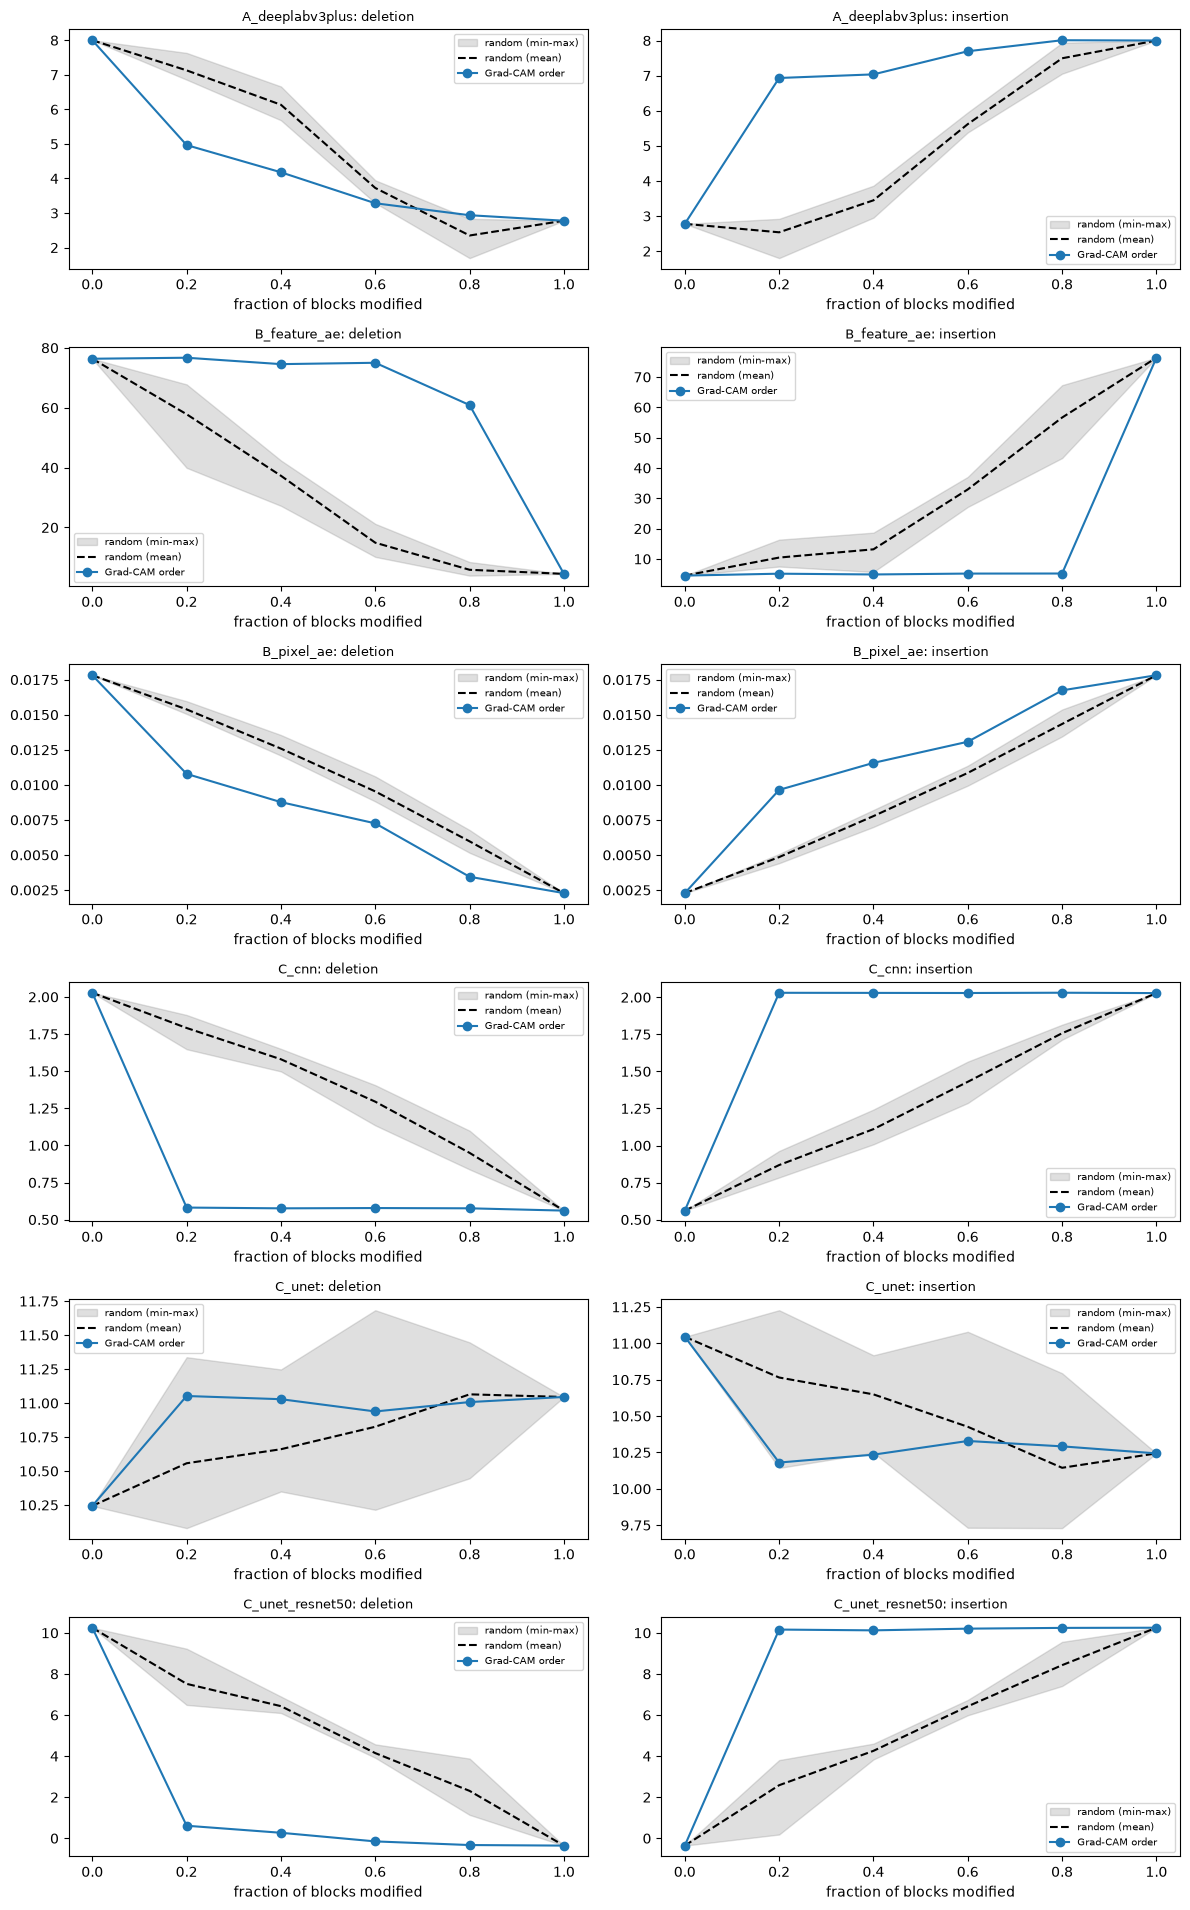

In [8]:
fractions = np.linspace(0, 1, 6)
fig, ax = plt.subplots(len(curves), 2, figsize=(12, 3.2 * len(curves)), squeeze=False, tight_layout=True)
for row, (name, result) in enumerate(curves.items()):
    for col, kind in enumerate(["deletion", "insertion"]):
        randoms = np.array([result[k][kind] for k in result if k.startswith("random")])
        ax[row, col].fill_between(fractions, randoms.min(0), randoms.max(0), color="gray", alpha=0.25, label="random (min-max)")
        ax[row, col].plot(fractions, randoms.mean(0), "k--", label="random (mean)")
        ax[row, col].plot(fractions, result["attribution"][kind], marker="o", label="Grad-CAM order")
        ax[row, col].set_title(f"{name}: {kind}", fontsize=9); ax[row, col].set_xlabel("fraction of blocks modified")
        ax[row, col].legend(fontsize=7)
plt.savefig(FIG_DIR / "6_04_deletion_insertion.png", dpi=70)
plt.show()

## 7. Reading the explanations
READING_PLACEHOLDER